# How-to 3 · A template from the data (TIRAVEL, HARPS TOI-193)

Measure RVs of 32 HARPS spectra against a PHOENIX template, use them to align and co-add the
spectra into a TIRAVEL template, then measure the RVs again against that template.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sparta import Observations, Template, instruments
from sparta.plotting import apply_style, plot_points

apply_style()        # SPARTA figure style: data black, model red, extra blue, maps grey

In [2]:
harps = instruments.get("HARPS")
rec = harps.recommended
obs = Observations(survey="HARPS", target_visits_lib="../data/TOI193/",
                   min_wv=rec.window_A[0], max_wv=rec.window_A[1])         # Angstrom
obs.preprocess(**rec.preprocess)
print(f"{obs.sample_size} epochs over {np.ptp(obs.time_list):.1f} days; "
      f"window {rec.window_A} Å, frame: {obs.wavelength_frame}")

32 epochs over 54.1 days; window (4990.0, 5090.0) Å, frame: air


In [3]:
# HARPS wavelengths are in air, PHOENIX in vacuum: air=True converts the model (Morton 2000).
library = Template.from_phoenix(5500, 4.5, wave_range=(4960, 5120), air=True, allow_download=False)
library.broaden_rotational(vsini=1.5, epsilon=0.5)                          # km/s
library.broaden_instrumental(resolution=harps.instrument.resolving_power)
library.model.preprocess(**rec.preprocess)

obs.calc_rv_against_template(library, dv=rec.dv_kms, vel_bound=150)
rv_library, erv_library = obs.vels.copy(), obs.evels.copy()
print(f"library template: mean RV {rv_library.mean():.3f} km/s, rms {rv_library.std() * 1e3:.1f} m/s, "
      f"median eRV {np.median(erv_library) * 1e3:.1f} m/s")

library template: mean RV -10.440 km/s, rms 14.1 m/s, median eRV 28.2 m/s


rho = 0.9973 (1 = perfectly aligned); n_eff = 32.0 of 32 epochs


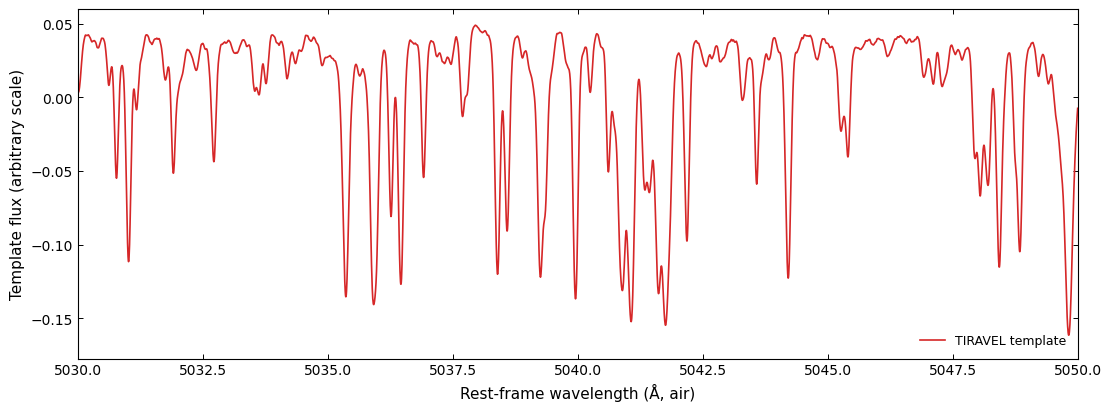

In [4]:
obs.build_tiravel_template(rv_library)                  # align at these RVs, co-add
tir = obs.tiravel
print(f"rho = {tir.rho:.4f} (1 = perfectly aligned); "
      f"n_eff = {tir.diagnostics['n_eff']:.1f} of {obs.sample_size} epochs")

fig = tir.plot_template(show_epochs=False)
fig.axes[0].set_xlim(5030, 5050)
fig.axes[0].set_xlabel("Rest-frame wavelength (Å, air)")
fig.axes[0].set_ylabel("Template flux (arbitrary scale)")
plt.show()

In [5]:
obs.calc_rv_against_template(obs.tiravel_template, dv=rec.dv_kms, vel_bound=150)
rv_tiravel = obs.vels.copy()
diff = rv_tiravel - rv_library
print(f"TIRAVEL template: rms {rv_tiravel.std() * 1e3:.1f} m/s, "
      f"median eRV {np.median(obs.evels) * 1e3:.1f} m/s")
print(f"TIRAVEL - library: mean {diff.mean() * 1e3:+.2f} m/s, rms {diff.std() * 1e3:.1f} m/s")

TIRAVEL template: rms 14.3 m/s, median eRV 2.0 m/s
TIRAVEL - library: mean +0.00 m/s, rms 2.2 m/s


TIRAVEL RVs inherit the zero point of the velocities used to build the template, so compare
them relative to their mean. The PHOENIX errors are larger because template mismatch counts as
noise (`docs/conventions.md`); only the TIRAVEL error bars are drawn.

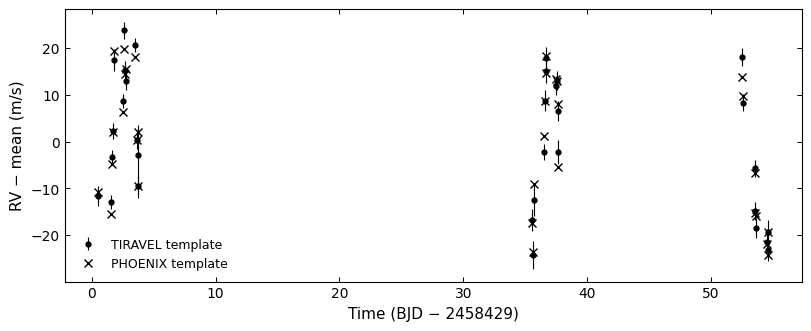

In [6]:
order = np.argsort(obs.time_list)
t = np.asarray(obs.time_list)[order]
fig, ax = plt.subplots()
plot_points(ax, t, (rv_tiravel - rv_tiravel.mean())[order] * 1e3, obs.evels[order] * 1e3,
            label="TIRAVEL template")
plot_points(ax, t, (rv_library - rv_library.mean())[order] * 1e3, fmt="x", ms=6,
            label="PHOENIX template")
ax.set_xlabel(f"Time (BJD − {obs.first_time})")
ax.set_ylabel("RV − mean (m/s)")
ax.legend()
plt.show()

## Go deeper

- TIRAVEL step by step and the alignment measure ρ: tutorial [`05_tiravel`](../tutorials/05_tiravel.ipynb).
- Why a HARPS template must be in air: [conventions § air and vacuum](../../docs/conventions.md#air-and-vacuum-wavelengths).
- What is implemented, how to read ρ and the weights, and what is not done yet: [TIRAVEL](../../docs/tiravel.md); the checklist: [good practices](../../docs/good_practices.md#tiravel).
- HARPS frames, sampling and the recommended settings: [instruments § HARPS](../../docs/instruments.md#harps).